# Modeling & evaluation — booking cancellation

Notebook này tạo baseline, tuning 4 thuật toán bằng Optuna với temporal CV, đánh giá trên cùng validation cohort, chọn threshold theo năng lực xử lý cảnh báo và xuất prediction/report khi chạy. Phạm vi model chính là population `individual`, theo thiết kế dự án; `group_block` cần quy tắc vận hành riêng.

**Sau khi đổi split và threshold policy, execution state cũ đã được xóa.** Restart Kernel rồi Run All để tránh dùng biến cũ; tuning chạy trong 4 cell Optuna riêng. Kết quả và file output được sinh khi chạy notebook.

## Giới hạn dữ liệu và cách chia thời gian
- Target: `is_canceled`. Chia theo `arrival_date`: train 2015-07-01 đến 2016-09-30; validation 2016-10-01 đến 2016-12-31; test 2017-01-01 đến 2017-08-31. Test chỉ được mở sau khi hoàn tất chọn model và threshold.
- Validation và cohort 2017 đã được xem trong notebook 03 EDA (xem `docs/F1_validation_design.md`); vì vậy đây là holdout theo workflow notebook này, **không phải untouched trong lịch sử dự án**. Kết quả 2017 cũng đã được xem trước đó.
- Dữ liệu nguồn là near-arrival snapshot. Một số trường, đặc biệt `lead_time` và các biến suy ra từ ngày đến/lead time, có thể khác giá trị thực sự biết tại thời điểm booking. Label maturity được xấp xỉ bằng `arrival_date` vì modeling dataset không có ngày label được xác nhận; đây là quy ước bảo thủ, không phải timestamp thực tế. Kết quả là retrospective prototype, không phải bằng chứng về hiệu năng production. Kiểm tra `docs/feature_availability.csv` và xác minh feature as-of trước triển khai.
- PR-AUC được tính bằng average precision (AP); event-rate baseline được báo cáo cạnh PR-AUC. Threshold provisional được chọn trên validation bằng F1 tối đa, không áp hard cap alert share. Alert share/queue vẫn được báo cáo để business quyết định capacity; threshold model cuối được đóng băng trước test.


In [8]:
# Nếu thiếu package, bỏ comment và chạy riêng dòng sau; notebook không cài package tự động.
# %pip install -r requirements.txt
from pathlib import Path
import json

from IPython.display import display
import joblib
import matplotlib.pyplot as plt
import numpy as np
try:
    import optuna
except ImportError as exc:
    raise ImportError('Cài dependencies bằng %pip install -r requirements.txt để dùng Optuna.') from exc
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError('Cài dependencies bằng %pip install -r requirements.txt để dùng XGBoost.') from exc

SEED = 42
N_TRIALS_PER_MODEL = 40  # separate Optuna studies; 4 models x 40 trials x 4 folds
ALERT_SHARE_REFERENCE = 0.20  # plot reference only; no capacity gate
MIN_SUBGROUP_SIZE = 100
np.random.seed(SEED)
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style='whitegrid')

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data' / 'processed' / 'modeling_dataset.csv').exists():
    candidates = [p for p in Path.cwd().parents if (p / 'data' / 'processed' / 'modeling_dataset.csv').exists()]
    if not candidates:
        raise FileNotFoundError('Không tìm thấy data/processed/modeling_dataset.csv; mở notebook từ thư mục gốc repo.')
    PROJECT_ROOT = candidates[0]
DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'modeling_dataset.csv'
OUTPUT_DIR = PROJECT_ROOT / 'artifacts' / 'modeling'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Project root:', PROJECT_ROOT)
print('Output folder:', OUTPUT_DIR)


Project root: c:\Users\Admin\OneDrive\Desktop\BA-Advance-Project---Group-2
Output folder: c:\Users\Admin\OneDrive\Desktop\BA-Advance-Project---Group-2\artifacts\modeling


## 1. Nạp dữ liệu, chọn feature và chia cohort theo thời gian

Model chính dùng `individual` theo `config/column_groups.json`; `group_block` cần policy riêng. Chia theo ngày đến (arrival cohort): **train 2015-07-01 đến 2016-09-30**, **validation 2016-10-01 đến 2016-12-31**, **test 2017-01-01 đến 2017-08-31** (test theo source `split == test`). Quý cuối 2016 dùng chọn model/threshold; test 2017 giữ cho đánh giá cuối. Đồ thị ngay dưới cho thấy quy mô theo tháng và event rate train/validation; test labels không được xem ở bước overview.

Feature lấy từ allow-list `individual_model`. Loại ID/target/split metadata, monetary snapshot và trường chỉ có ở pre-arrival; `lead_time` vẫn là near-arrival snapshot nên phân tích lead-time chỉ mang tính diagnostic nếu chưa xác minh as-of.


In [14]:
df = pd.read_csv(DATA_PATH, parse_dates=['arrival_date', 'booking_date'])
if not {'is_canceled', 'arrival_date', 'split', 'population'}.issubset(df.columns):
    raise ValueError('Dataset cần is_canceled, arrival_date, split và population.')

column_config = json.loads((PROJECT_ROOT / 'config' / 'column_groups.json').read_text(encoding='utf-8'))
individual_config = column_config['individual_model']
pre_arrival_only = set(individual_config['pre_arrival_extra'])
snapshot_monetary = {'adr_clean', 'adr_vs_ref', 'adr_per_guest'}
numeric_candidates = [c for c in individual_config['numeric']
                      if c not in pre_arrival_only and c not in snapshot_monetary]
categorical_candidates = [c for c in individual_config['categorical'] if c not in pre_arrival_only]
numeric_features = [c for c in numeric_candidates if c in df.columns]
categorical_features = [c for c in categorical_candidates if c in df.columns]
not_found_features = [c for c in numeric_candidates + categorical_candidates if c not in df.columns]
feature_cols = numeric_features + categorical_features
if not feature_cols:
    raise ValueError('Không tìm thấy feature hợp lệ trong modeling_dataset.csv.')
print(f'{len(numeric_features)} numeric, {len(categorical_features)} categorical features')
print('Unavailable configured columns:', not_found_features)

# individual là population cho classifier chính; group_block có quyết định vận hành riêng.
individual = df['population'].eq('individual')
arrival = df['arrival_date']
train_mask = individual & df['split'].eq('train') & arrival.between('2015-07-01', '2016-09-30')
validation_mask = individual & df['split'].eq('train') & arrival.between('2016-10-01', '2016-12-31')
test_mask = individual & df['split'].eq('test') & arrival.between('2017-01-01', '2017-08-31')
train = df.loc[train_mask].copy()
validation = df.loc[validation_mask].copy()
test = df.loc[test_mask].copy()
if min(len(train), len(validation), len(test)) == 0:
    raise ValueError('Cohort rỗng; kiểm tra date và source split.')
assert train['arrival_date'].max() < validation['arrival_date'].min()
assert validation['arrival_date'].max() < test['arrival_date'].min()
assert set(train.index).isdisjoint(validation.index)
assert set(train.index).isdisjoint(test.index)
assert set(validation.index).isdisjoint(test.index)

for name, part in [('train', train), ('validation', validation)]:
    if part['is_canceled'].isna().any() or not set(part['is_canceled'].unique()).issubset({0, 1}):
        raise ValueError(f'{name} cần nhãn is_canceled nhị phân 0/1, không null.')
cohort_summary = pd.DataFrame([
    {'cohort': name, 'rows': len(part), 'start': part['arrival_date'].min().date(),
     'end': part['arrival_date'].max().date(), 'event_rate': part['is_canceled'].mean()}
    for name, part in [('train', train), ('validation', validation)]
] + [{'cohort': 'test (labels held until final evaluation)', 'rows': len(test),
      'start': test['arrival_date'].min().date(), 'end': test['arrival_date'].max().date(),
      'event_rate': 'not read yet'}])
display(cohort_summary)
print('Historical caveat: notebook 03 EDA previously viewed 2016/2017 labels.')

X_train, y_train = train[feature_cols], train['is_canceled'].astype(int)
X_val, y_val = validation[feature_cols], validation['is_canceled'].astype(int)
train_event_rate = float(y_train.mean())
print(f'Train event-rate baseline (constant prediction): {train_event_rate:.4f}')


33 numeric, 7 categorical features
Unavailable configured columns: []


,cohort,rows,start,end,event_rate
0,train,25418,2015-07-01,2016-09-30,0.267448
1,validation,6859,2016-10-01,2016-12-31,0.328328
2,test (labels held until final evaluation),20399,2017-01-01,2017-08-31,not read yet


Historical caveat: notebook 03 EDA previously viewed 2016/2017 labels.
Train event-rate baseline (constant prediction): 0.2674


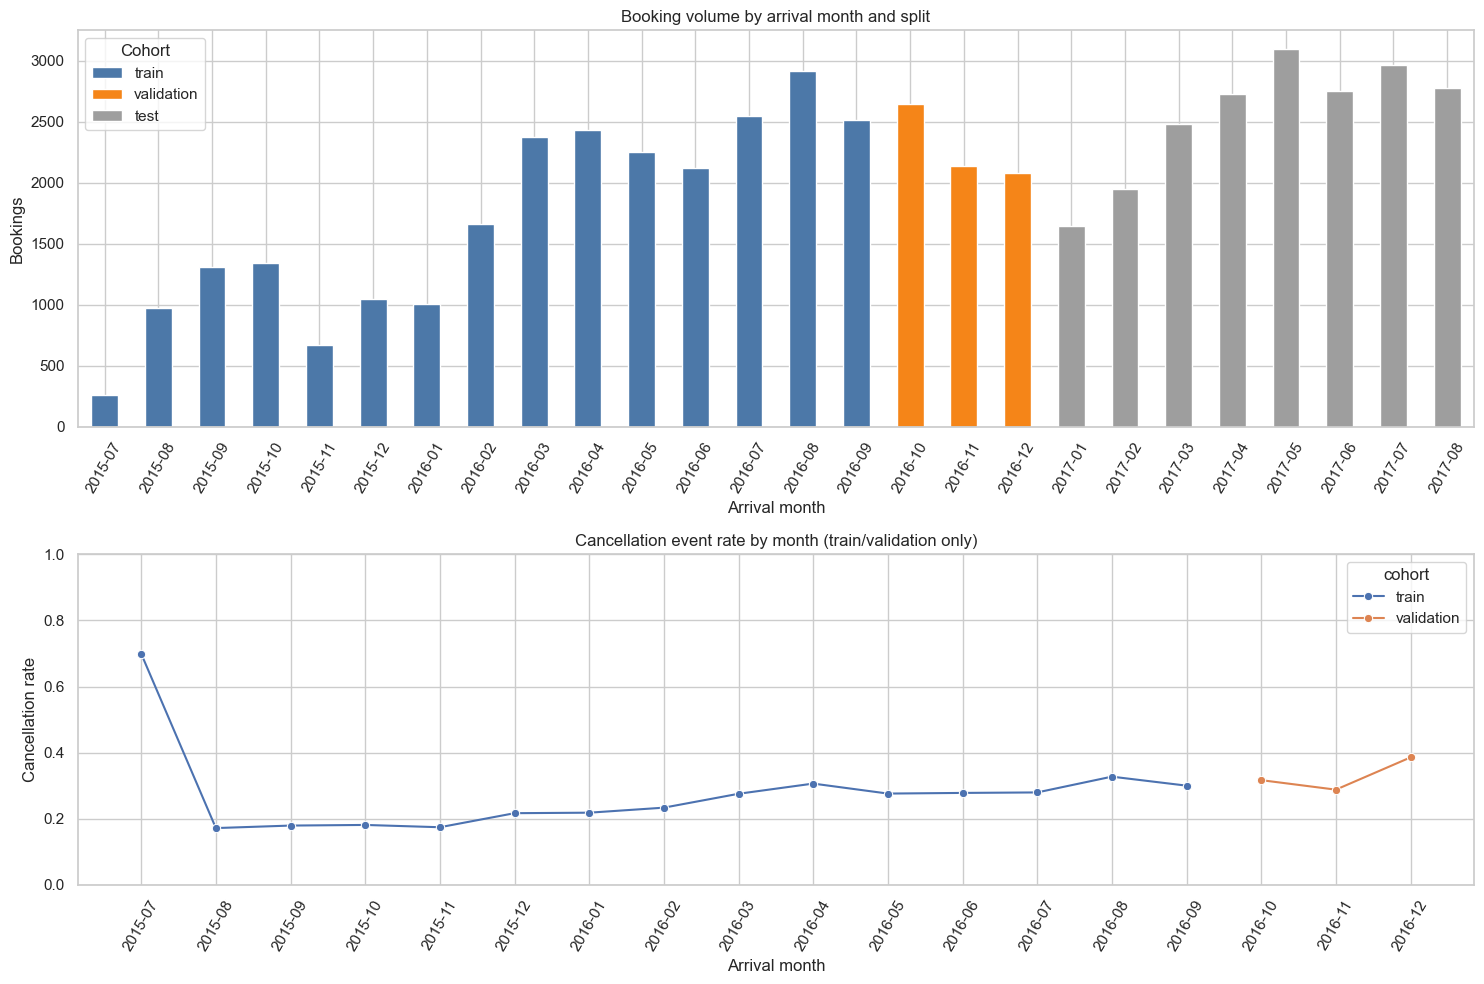

cohort,train,validation,test
arrival_month,,,
2015-07,256,0,0
2015-08,969,0,0
2015-09,1308,0,0
2015-10,1344,0,0
2015-11,673,0,0
2015-12,1049,0,0
2016-01,1005,0,0
2016-02,1660,0,0
2016-03,2373,0,0


Test is included in volume/date overview only; its labels/event rate remain hidden until final evaluation.


In [15]:
# Dataset overview after the chronological split. Test outcomes stay hidden until final evaluation.
cohort_parts = []
for cohort_name, cohort_df in [('train', train), ('validation', validation), ('test', test)]:
    part = cohort_df[['arrival_date']].copy()
    part['cohort'] = cohort_name
    part['arrival_month'] = part['arrival_date'].dt.to_period('M').astype(str)
    if cohort_name != 'test':
        part['is_canceled'] = cohort_df['is_canceled'].to_numpy()
    cohort_parts.append(part)
overview_rows = pd.concat(cohort_parts, ignore_index=True)
monthly_counts = overview_rows.groupby(['arrival_month', 'cohort'], observed=True).size().unstack(fill_value=0)
monthly_counts = monthly_counts.reindex(columns=['train', 'validation', 'test'], fill_value=0)

train_val_for_rate = pd.concat([
    train[['arrival_date', 'is_canceled']].assign(cohort='train'),
    validation[['arrival_date', 'is_canceled']].assign(cohort='validation')
], ignore_index=True)
train_val_for_rate['arrival_month'] = train_val_for_rate['arrival_date'].dt.to_period('M').astype(str)
monthly_event_rate = (train_val_for_rate.groupby(['arrival_month', 'cohort'], observed=True)['is_canceled']
                      .mean().reset_index(name='event_rate'))

fig, axes = plt.subplots(2, 1, figsize=(15, 10), gridspec_kw={'height_ratios': [1.2, 1]})
monthly_counts.plot(kind='bar', stacked=True, ax=axes[0], color=['#4C78A8', '#F58518', '#9E9E9E'])
axes[0].set(title='Booking volume by arrival month and split', xlabel='Arrival month', ylabel='Bookings')
axes[0].legend(title='Cohort')
axes[0].tick_params(axis='x', rotation=60)
sns.lineplot(data=monthly_event_rate, x='arrival_month', y='event_rate', hue='cohort', marker='o', ax=axes[1])
axes[1].set(title='Cancellation event rate by month (train/validation only)',
            xlabel='Arrival month', ylabel='Cancellation rate', ylim=(0, 1))
axes[1].tick_params(axis='x', rotation=60)
plt.tight_layout()
plt.show()
display(monthly_counts)
print('Test is included in volume/date overview only; its labels/event rate remain hidden until final evaluation.')

## 2. Temporal CV và tuning từng model riêng

Bốn expanding-origin folds theo quý, chỉ trong train cohort: Q4/2015, Q1/2016, Q2/2016, Q3/2016. Mỗi fold chỉ fit trên dữ liệu trước quý validation; preprocessing cũng fit lại bên trong fold. Mỗi thuật toán có cell Optuna riêng và 40 trials mặc định, có thể chỉnh độc lập trong setup. Validation Q4/2016/test 2017 không tham gia tuning. One-hot được densify cho HistGradientBoosting; memory hiện phù hợp dataset này.


In [16]:
FOLD_WINDOWS = [
    ('fold_1', '2015-09-30', '2015-10-01', '2015-12-31'),
    ('fold_2', '2015-12-31', '2016-01-01', '2016-03-31'),
    ('fold_3', '2016-03-31', '2016-04-01', '2016-06-30'),
    ('fold_4', '2016-06-30', '2016-07-01', '2016-09-30'),
]
folds = []
for fold_name, fit_end, valid_start, valid_end in FOLD_WINDOWS:
    fit_idx = train.index[train['arrival_date'].le(pd.Timestamp(fit_end))]
    valid_idx = train.index[train['arrival_date'].between(valid_start, valid_end)]
    if len(fit_idx) == 0 or len(valid_idx) == 0:
        raise ValueError(f'{fold_name} rỗng; kiểm tra temporal split.')
    if y_train.loc[fit_idx].nunique() != 2 or y_train.loc[valid_idx].nunique() != 2:
        raise ValueError(f'{fold_name} cần đủ 2 classes ở fit và validation.')
    assert train.loc[fit_idx, 'arrival_date'].max() < train.loc[valid_idx, 'arrival_date'].min()
    folds.append((fold_name, fit_idx, valid_idx))
display(pd.DataFrame([{
    'fold': name, 'fit_rows': len(fit_idx), 'fit_through': train.loc[fit_idx, 'arrival_date'].max().date(),
    'valid_rows': len(valid_idx), 'valid_from': train.loc[valid_idx, 'arrival_date'].min().date(),
    'valid_to': train.loc[valid_idx, 'arrival_date'].max().date()
} for name, fit_idx, valid_idx in folds]))

baseline_features = [c for c in ['lead_time', 'market_segment'] if c in feature_cols]
baseline_numeric = [c for c in baseline_features if c in numeric_features]
baseline_categorical = [c for c in baseline_features if c in categorical_features]
if not baseline_features:
    raise ValueError('Baseline logistic regression cần lead_time hoặc market_segment.')

MODEL_NAMES = ['logistic_regression', 'random_forest', 'xgboost', 'hist_gradient_boosting']

def make_pipeline(model_name, params=None):
    params = dict(params or {})
    scale_numeric = model_name == 'logistic_regression'
    numeric_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale_numeric:
        numeric_steps.append(('scale', StandardScaler()))
    transformers = [('num', Pipeline(numeric_steps), numeric_features)]
    if categorical_features:
        transformers.append(('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), categorical_features))
    prep = ColumnTransformer(transformers, remainder='drop', sparse_threshold=0.0)
    if model_name == 'logistic_regression':
        estimator = LogisticRegression(class_weight='balanced', max_iter=4000, random_state=SEED, **params)
    elif model_name == 'random_forest':
        estimator = RandomForestClassifier(class_weight='balanced_subsample', n_jobs=-1,
                                           random_state=SEED, **params)
    elif model_name == 'xgboost':
        estimator = XGBClassifier(objective='binary:logistic', eval_metric='logloss', n_jobs=-1,
                                  tree_method='hist', random_state=SEED, **params)
    elif model_name == 'hist_gradient_boosting':
        estimator = HistGradientBoostingClassifier(early_stopping=False, random_state=SEED, **params)
    else:
        raise ValueError(f'Unknown model: {model_name}')
    return Pipeline([('preprocess', prep), ('model', estimator)])

def make_baseline_pipeline():
    transformers = []
    if baseline_numeric:
        transformers.append(('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                                              ('scale', StandardScaler())]), baseline_numeric))
    if baseline_categorical:
        transformers.append(('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), baseline_categorical))
    prep = ColumnTransformer(transformers, remainder='drop', sparse_threshold=0.0)
    return Pipeline([('preprocess', prep), ('model', LogisticRegression(
        class_weight='balanced', max_iter=4000, random_state=SEED))])

def suggest_params(trial, model_name):
    if model_name == 'logistic_regression':
        return {'C': trial.suggest_float('C', 1e-4, 1e3, log=True),
                'solver': trial.suggest_categorical('solver', ['lbfgs', 'liblinear'])}
    if model_name == 'random_forest':
        return {'n_estimators': trial.suggest_int('n_estimators', 300, 800, step=100),
                'max_depth': trial.suggest_categorical('max_depth', [None, 6, 10, 14, 20, 30]),
                'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 25),
                'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5, 0.8])}
    if model_name == 'xgboost':
        return {'n_estimators': trial.suggest_int('n_estimators', 300, 900, step=100),
                'max_depth': trial.suggest_int('max_depth', 2, 9),
                'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.25, log=True),
                'subsample': trial.suggest_float('subsample', 0.65, 1.0),
                'colsample_bytree': trial.suggest_float('colsample_bytree', 0.65, 1.0),
                'min_child_weight': trial.suggest_float('min_child_weight', 1, 15),
                'reg_lambda': trial.suggest_float('reg_lambda', 1e-2, 50, log=True)}
    if model_name == 'hist_gradient_boosting':
        return {'max_iter': trial.suggest_int('max_iter', 150, 600, step=50),
                'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.25, log=True),
                'max_leaf_nodes': trial.suggest_int('max_leaf_nodes', 15, 63),
                'l2_regularization': trial.suggest_float('l2_regularization', 1e-5, 20, log=True),
                'min_samples_leaf': trial.suggest_int('min_samples_leaf', 10, 60)}
    raise ValueError(f'No Optuna search space for {model_name}.')

def tune_temporal_model(model_name, n_trials=N_TRIALS_PER_MODEL):
    def objective(trial):
        params = suggest_params(trial, model_name)
        scores = []
        for _, fit_idx, valid_idx in folds:
            estimator = make_pipeline(model_name, params)
            estimator.fit(train.loc[fit_idx, feature_cols], y_train.loc[fit_idx])
            probability = estimator.predict_proba(train.loc[valid_idx, feature_cols])[:, 1]
            scores.append(average_precision_score(y_train.loc[valid_idx], probability))
        trial.set_user_attr('fold_scores', scores)
        return float(np.mean(scores))
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=n_trials, show_progress_bar=False)
    return study


,fold,fit_rows,fit_through,valid_rows,valid_from,valid_to
0,fold_1,2533,2015-09-30,3066,2015-10-01,2015-12-31
1,fold_2,5599,2015-12-31,5038,2016-01-01,2016-03-31
2,fold_3,10637,2016-03-31,6803,2016-04-01,2016-06-30
3,fold_4,17440,2016-06-30,7978,2016-07-01,2016-09-30


### Optuna — Logistic Regression
Chạy/tăng trial độc lập với `N_TRIALS_PER_MODEL`.


In [17]:
study_logistic_regression = tune_temporal_model('logistic_regression')
print('Logistic Regression best CV AP:', study_logistic_regression.best_value)
print('Best parameters:', study_logistic_regression.best_params)
print('Fold AP:', study_logistic_regression.best_trial.user_attrs['fold_scores'])

Logistic Regression best CV AP: 0.5091008036574547
Best parameters: {'C': 80.1851404490943, 'solver': 'liblinear'}
Fold AP: [0.7516676189516246, 0.3922841941199814, 0.4481177694100077, 0.4443336321482053]


### Optuna — Random Forest
Study riêng; không chia sẻ trial/parameter với model khác.


In [18]:
study_random_forest = tune_temporal_model('random_forest')
print('Random Forest best CV AP:', study_random_forest.best_value)
print('Best parameters:', study_random_forest.best_params)
print('Fold AP:', study_random_forest.best_trial.user_attrs['fold_scores'])

Random Forest best CV AP: 0.5141642100573333
Best parameters: {'n_estimators': 500, 'max_depth': 6, 'min_samples_leaf': 5, 'max_features': 'log2'}
Fold AP: [0.7682629052716554, 0.42394479305078014, 0.4348873095017407, 0.4295618324051566]


### Optuna — XGBoost
Study riêng; có thể chạy lại riêng cell này để tune XGBoost.


In [19]:
study_xgboost = tune_temporal_model('xgboost')
print('XGBoost best CV AP:', study_xgboost.best_value)
print('Best parameters:', study_xgboost.best_params)
print('Fold AP:', study_xgboost.best_trial.user_attrs['fold_scores'])

XGBoost best CV AP: 0.5110177968786337
Best parameters: {'n_estimators': 500, 'max_depth': 6, 'learning_rate': 0.010356648918421942, 'subsample': 0.7370053706840297, 'colsample_bytree': 0.9077025807960128, 'min_child_weight': 10.084083687301844, 'reg_lambda': 17.022743751157847}
Fold AP: [0.7624481953727549, 0.41595984672558217, 0.4402931433662155, 0.4253700020499823]


### Optuna — HistGradientBoosting
Study riêng; không chia sẻ trial/parameter với model khác.


In [20]:
study_hist_gradient_boosting = tune_temporal_model('hist_gradient_boosting')
print('HistGradientBoosting best CV AP:', study_hist_gradient_boosting.best_value)
print('Best parameters:', study_hist_gradient_boosting.best_params)
print('Fold AP:', study_hist_gradient_boosting.best_trial.user_attrs['fold_scores'])

HistGradientBoosting best CV AP: 0.5125169555168303
Best parameters: {'max_iter': 250, 'learning_rate': 0.02124498545468689, 'max_leaf_nodes': 45, 'l2_regularization': 0.013742462322876401, 'min_samples_leaf': 25}
Fold AP: [0.7708219982430826, 0.42827155275760176, 0.4420953121989018, 0.40887895886773507]


In [21]:
studies = {
    'logistic_regression': study_logistic_regression,
    'random_forest': study_random_forest,
    'xgboost': study_xgboost,
    'hist_gradient_boosting': study_hist_gradient_boosting,
}
best_params = {name: study.best_params for name, study in studies.items()}
cv_summary = []
for name, study in studies.items():
    scores = np.asarray(study.best_trial.user_attrs['fold_scores'], dtype=float)
    cv_summary.append({'model': name, 'cv_pr_auc_mean': scores.mean(),
                       'cv_pr_auc_std': scores.std(ddof=1), 'cv_pr_auc_min': scores.min(),
                       'cv_pr_auc_max': scores.max(), 'best_params': json.dumps(study.best_params),
                       **{f'{folds[i][0]}_pr_auc': score for i, score in enumerate(scores)}})

# Reference baseline evaluated with the same expanding temporal folds.
baseline_fold_scores = []
for _, fit_idx, valid_idx in folds:
    baseline_fold = make_baseline_pipeline()
    baseline_fold.fit(train.loc[fit_idx, baseline_features], y_train.loc[fit_idx])
    probability = baseline_fold.predict_proba(train.loc[valid_idx, baseline_features])[:, 1]
    baseline_fold_scores.append(average_precision_score(y_train.loc[valid_idx], probability))
baseline_scores = np.asarray(baseline_fold_scores, dtype=float)
cv_summary.append({'model': 'baseline_logistic', 'cv_pr_auc_mean': baseline_scores.mean(),
                   'cv_pr_auc_std': baseline_scores.std(ddof=1), 'cv_pr_auc_min': baseline_scores.min(),
                   'cv_pr_auc_max': baseline_scores.max(), 'best_params': '{}',
                   **{f'{folds[i][0]}_pr_auc': score for i, score in enumerate(baseline_scores)}})
cv_results = pd.DataFrame(cv_summary).set_index('model')
display(cv_results)
print('CV score is mean average precision across four chronological validation quarters; inspect fold spread for drift.')

,cv_pr_auc_mean,cv_pr_auc_std,cv_pr_auc_min,cv_pr_auc_max,best_params,fold_1_pr_auc,fold_2_pr_auc,fold_3_pr_auc,fold_4_pr_auc
model,,,,,,,,,
logistic_regression,0.509101,0.163706,0.392284,0.751668,"{""C"": 80.1851404490943, ""solver"": ""liblinear""}",0.751668,0.392284,0.448118,0.444334
random_forest,0.514164,0.169458,0.423945,0.768263,"{""n_estimators"": 500, ""max_depth"": 6, ""min_sam...",0.768263,0.423945,0.434887,0.429562
xgboost,0.511018,0.167919,0.415960,0.762448,"{""n_estimators"": 500, ""max_depth"": 6, ""learnin...",0.762448,0.415960,0.440293,0.425370
hist_gradient_boosting,0.512517,0.172741,0.408879,0.770822,"{""max_iter"": 250, ""learning_rate"": 0.021244985...",0.770822,0.428272,0.442095,0.408879
baseline_logistic,0.326969,0.049994,0.259927,0.380612,{},0.259927,0.337925,0.329412,0.380612


CV score is mean average precision across four chronological validation quarters; inspect fold spread for drift.


## 3. Refit trên toàn bộ training cohort và đánh giá validation

Mỗi model tuned được fit lại từ đầu trên toàn bộ train (2015-07 đến 2016-09) với best params. So sánh trên cùng validation cohort (Q4/2016). Baseline gồm constant event rate và logistic regression (lead time + market segment). Threshold provisional tối ưu F1 trên validation; không áp giới hạn alert share 20%. Báo cáo threshold 0.5 song song để đối chiếu, và hiển thị queue volume để business chọn capacity phù hợp.


In [22]:
fitted_models = {}
for model_name in MODEL_NAMES:
    fitted_models[model_name] = make_pipeline(model_name, best_params[model_name])
    fitted_models[model_name].fit(X_train, y_train)
baseline_pipeline = make_baseline_pipeline()
baseline_pipeline.fit(train[baseline_features], y_train)
fitted_models['baseline_logistic'] = baseline_pipeline
val_probabilities = {
    name: model.predict_proba(X_val if name != 'baseline_logistic' else validation[baseline_features])[:, 1]
    for name, model in fitted_models.items()
}
val_probabilities['constant_event_rate'] = np.full(len(validation), train_event_rate, dtype=float)
for name, probability in val_probabilities.items():
    if len(probability) != len(validation) or not np.isfinite(probability).all():
        raise ValueError(f'Invalid validation probabilities for {name}.')

def choose_threshold(y_true, probability):
    precision, recall, thresholds = precision_recall_curve(y_true, probability)
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    best = np.flatnonzero(np.isclose(f1, np.nanmax(f1)))
    # F1 is primary; ties prefer precision, then a threshold closer to the familiar 0.5.
    idx = max(best, key=lambda i: (precision[i], -abs(thresholds[i] - 0.5), thresholds[i]))
    return float(thresholds[idx])

def score_at_threshold(y_true, probability, threshold):
    pred = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    precision_value = precision_score(y_true, pred, zero_division=0)
    recall_value = recall_score(y_true, pred, zero_division=0)
    return {'precision': precision_value, 'recall': recall_value,
            'f1': 2 * precision_value * recall_value / max(precision_value + recall_value, 1e-12),
            'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
            'alert_share': float(pred.mean()), 'alerts_in_cohort': int(pred.sum()),
            'queue_per_1000': float(pred.mean() * 1000)}

validation_event_rate = float(y_val.mean())
metric_rows, validation_thresholds = [], {}
for name, probability in val_probabilities.items():
    threshold = 0.5 if name == 'constant_event_rate' else choose_threshold(y_val.to_numpy(), probability)
    validation_thresholds[name] = threshold
    threshold_metrics = score_at_threshold(y_val.to_numpy(), probability, threshold)
    fixed_metrics = score_at_threshold(y_val.to_numpy(), probability, 0.5)
    metric_rows.append({'model': name, 'validation_pr_auc': average_precision_score(y_val, probability),
                        'validation_event_rate_baseline': validation_event_rate,
                        'validation_roc_auc': roc_auc_score(y_val, probability),
                        'validation_brier': brier_score_loss(y_val, probability),
                        'threshold_policy': 'F1-max on validation' if name != 'constant_event_rate' else '0.5 reference',
                        'threshold': threshold, **threshold_metrics,
                        'precision_at_0_5': fixed_metrics['precision'],
                        'recall_at_0_5': fixed_metrics['recall'],
                        'alert_share_at_0_5': fixed_metrics['alert_share']})
validation_metrics = pd.DataFrame(metric_rows).set_index('model')
validation_metrics = validation_metrics.join(cv_results[['cv_pr_auc_mean', 'cv_pr_auc_std']], how='left')
display(validation_metrics.sort_values('validation_pr_auc', ascending=False))
print('Threshold rule: F1-max on the shared validation cohort; no hard alert-share cap.')
print('The selected threshold is provisional and must be frozen before final test evaluation.')


,validation_pr_auc,validation_event_rate_baseline,validation_roc_auc,validation_brier,threshold_policy,threshold,precision,recall,f1,tn,...,fn,tp,alert_share,alerts_in_cohort,queue_per_1000,precision_at_0_5,recall_at_0_5,alert_share_at_0_5,cv_pr_auc_mean,cv_pr_auc_std
model,,,,,,,,,,,,,,,,,,,,,
random_forest,0.576144,0.328328,0.747154,0.204378,F1-max on validation,0.485855,0.501146,0.776643,0.609195,2866,...,503,1749,0.508821,3490,508.820528,0.501882,0.769538,0.503426,0.514164,0.169458
xgboost,0.564615,0.328328,0.746171,0.198702,F1-max on validation,0.185898,0.482408,0.821936,0.607982,2621,...,401,1851,0.559411,3837,559.410993,0.718876,0.079485,0.036303,0.511018,0.167919
hist_gradient_boosting,0.557521,0.328328,0.740752,0.206447,F1-max on validation,0.162020,0.490614,0.765986,0.598128,2816,...,527,1725,0.512611,3516,512.611168,0.721569,0.081705,0.037177,0.512517,0.172741
logistic_regression,0.530750,0.328328,0.735507,0.199128,F1-max on validation,0.468887,0.493098,0.793073,0.608104,2771,...,466,1786,0.528065,3622,528.065316,0.500584,0.761101,0.499198,0.509101,0.163706
baseline_logistic,0.488093,0.328328,0.696503,0.233515,F1-max on validation,0.512672,0.440102,0.845027,0.578771,2186,...,349,1903,0.630413,4324,630.412597,0.397159,0.881439,0.728678,0.326969,0.049994
constant_event_rate,0.328328,0.328328,0.500000,0.224235,0.5 reference,0.500000,0.000000,0.000000,0.000000,4607,...,2252,0,0.000000,0,0.000000,0.000000,0.000000,0.000000,NaN,NaN


Threshold rule: F1-max on the shared validation cohort; no hard alert-share cap.
The selected threshold is provisional and must be frozen before final test evaluation.


## 4. Chọn model cuối — PR-AUC, calibration và vận hành

Không loại model bằng giới hạn alert share tuỳ ý. Lấy các model trong vòng 0.01 validation PR-AUC của model đứng đầu; trong nhóm sát nhau, ưu tiên Brier thấp, sau đó temporal CV mean cao và fold variability thấp, rồi độ đơn giản/reproducibility (Logistic Regression → HistGradientBoosting → Random Forest → XGBoost). Dùng precision/recall/F1 và queue volume ở F1-max threshold để kiểm tra tính vận hành; alert share 20% chỉ là mốc tham khảo trên graph, không phải điều kiện chọn. Constant/event-rate và baseline LR chỉ để so sánh, không phải candidate mặc định.


In [24]:
COMPLEXITY_ORDER = {'logistic_regression': 0, 'baseline_logistic': 1,
                    'hist_gradient_boosting': 2, 'random_forest': 3, 'xgboost': 4}
learned = validation_metrics.loc[[name for name in validation_metrics.index
                                  if name not in {'constant_event_rate', 'baseline_logistic'}]].copy()
top_ap = learned['validation_pr_auc'].max()
near_top = learned.loc[learned['validation_pr_auc'].ge(top_ap - 0.01)].copy()
near_top['cv_sort'] = near_top['cv_pr_auc_mean'].fillna(-1.0)
near_top['cv_stability_sort'] = near_top['cv_pr_auc_std'].fillna(np.inf)
near_top['complexity_rank'] = [COMPLEXITY_ORDER[name] for name in near_top.index]
near_top = near_top.sort_values(['validation_brier', 'cv_sort', 'cv_stability_sort', 'complexity_rank'],
                                ascending=[True, False, True, True])
selected_model_name = near_top.index[0]
selected_threshold = float(validation_thresholds[selected_model_name])
selection_table = validation_metrics.copy()
selection_table['within_20pct_alert_reference'] = selection_table['alert_share'].le(ALERT_SHARE_REFERENCE)
selection_table['selected'] = selection_table.index == selected_model_name
display(selection_table.sort_values(['selected', 'validation_pr_auc'], ascending=[False, False]))
print('Selected model:', selected_model_name)
print('Frozen F1-max threshold:', selected_threshold)
print('Validation alert share:', validation_metrics.loc[selected_model_name, 'alert_share'])
print('Selection uses validation AP, Brier, temporal CV mean/fold stability and model complexity; no hard capacity gate.')

validation_rows = []
for name, probability in val_probabilities.items():
    validation_rows.append(pd.DataFrame({'booking_id': validation['booking_id'].to_numpy(),
                                         'arrival_date': validation['arrival_date'].to_numpy(),
                                         'is_canceled': y_val.to_numpy(), 'model': name,
                                         'predicted_probability': probability,
                                         'threshold': validation_thresholds[name],
                                         'predicted_label': (probability >= validation_thresholds[name]).astype(int)}))
validation_predictions_all = pd.concat(validation_rows, ignore_index=True)
validation_predictions_best = validation_predictions_all.loc[
    validation_predictions_all['model'].eq(selected_model_name)].copy()


,validation_pr_auc,validation_event_rate_baseline,validation_roc_auc,validation_brier,threshold_policy,threshold,precision,recall,f1,tn,...,alert_share,alerts_in_cohort,queue_per_1000,precision_at_0_5,recall_at_0_5,alert_share_at_0_5,cv_pr_auc_mean,cv_pr_auc_std,within_20pct_alert_reference,selected
model,,,,,,,,,,,,,,,,,,,,,
random_forest,0.576144,0.328328,0.747154,0.204378,F1-max on validation,0.485855,0.501146,0.776643,0.609195,2866,...,0.508821,3490,508.820528,0.501882,0.769538,0.503426,0.514164,0.169458,False,True
xgboost,0.564615,0.328328,0.746171,0.198702,F1-max on validation,0.185898,0.482408,0.821936,0.607982,2621,...,0.559411,3837,559.410993,0.718876,0.079485,0.036303,0.511018,0.167919,False,False
hist_gradient_boosting,0.557521,0.328328,0.740752,0.206447,F1-max on validation,0.162020,0.490614,0.765986,0.598128,2816,...,0.512611,3516,512.611168,0.721569,0.081705,0.037177,0.512517,0.172741,False,False
logistic_regression,0.530750,0.328328,0.735507,0.199128,F1-max on validation,0.468887,0.493098,0.793073,0.608104,2771,...,0.528065,3622,528.065316,0.500584,0.761101,0.499198,0.509101,0.163706,False,False
baseline_logistic,0.488093,0.328328,0.696503,0.233515,F1-max on validation,0.512672,0.440102,0.845027,0.578771,2186,...,0.630413,4324,630.412597,0.397159,0.881439,0.728678,0.326969,0.049994,False,False
constant_event_rate,0.328328,0.328328,0.500000,0.224235,0.5 reference,0.500000,0.000000,0.000000,0.000000,4607,...,0.000000,0,0.000000,0.000000,0.000000,0.000000,NaN,NaN,True,False


Selected model: random_forest
Frozen F1-max threshold: 0.48585462746443586
Validation alert share: 0.508820527773728
Selection uses validation AP, Brier, temporal CV mean/fold stability and model complexity; no hard capacity gate.


## 5. Đồ thị và giải thích model

Các plot dưới đây dùng validation. Calibration plot/Brier giúp đánh giá chất lượng xác suất; permutation importance trên validation là mức ảnh hưởng dự báo mang tính exploratory, không phải causal effect. Market segment và lead-time band là phân tích subgroup, không đưa target/leakage fields vào phép nhóm ngoài mục đích báo cáo.


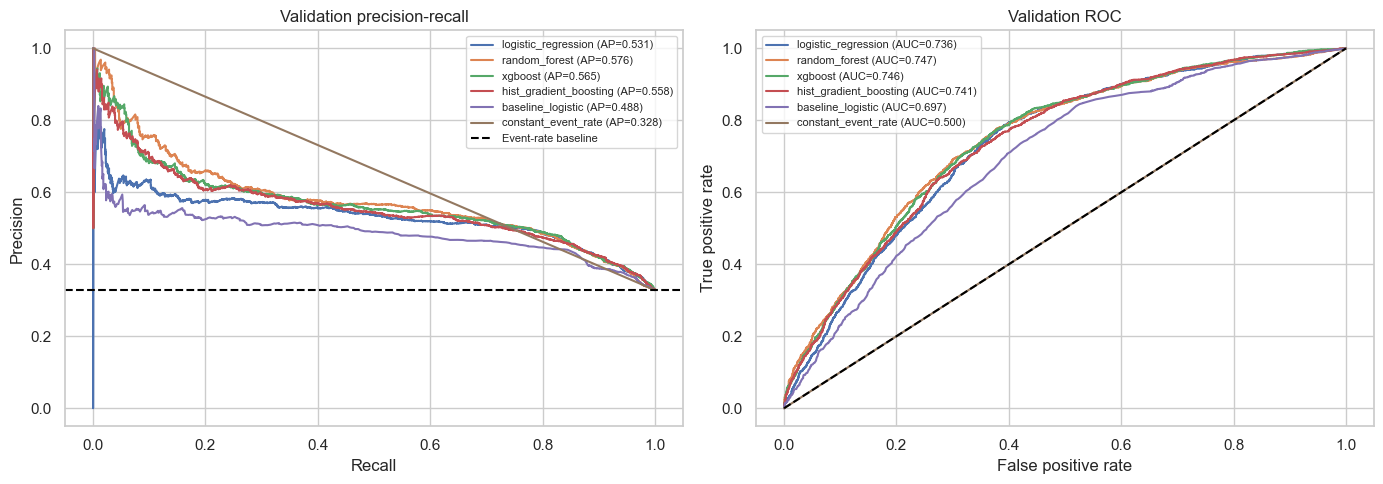

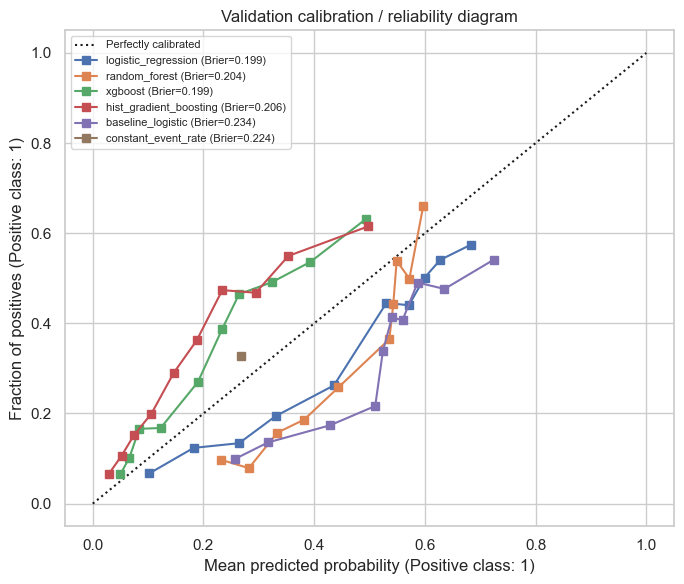

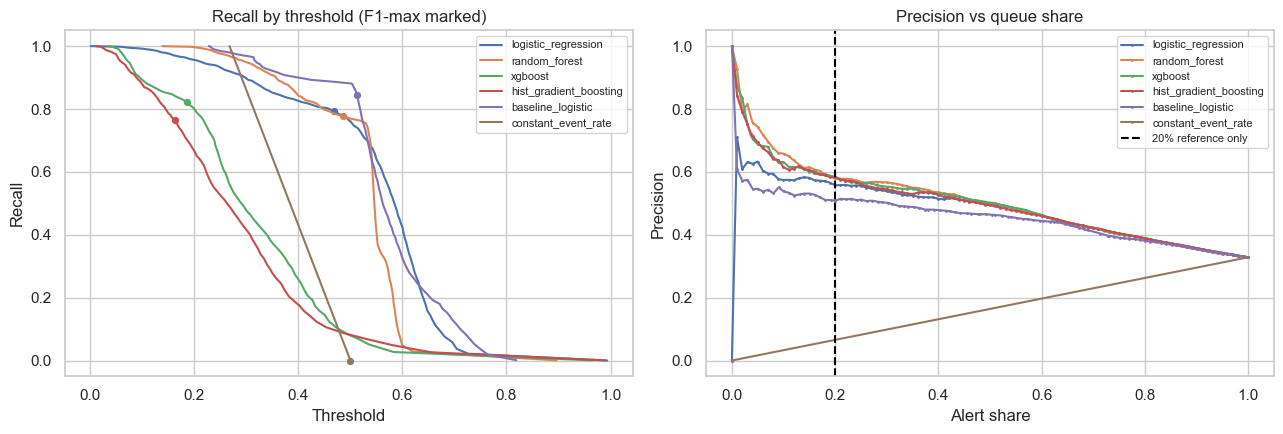

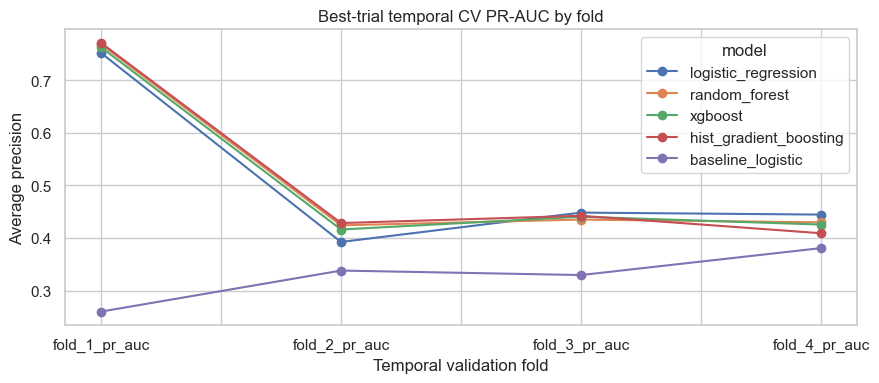

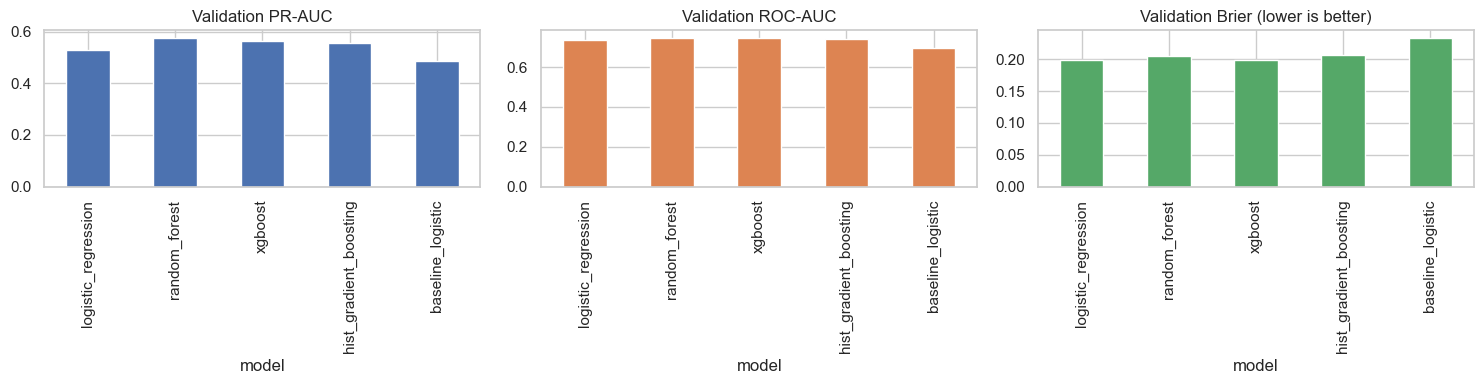

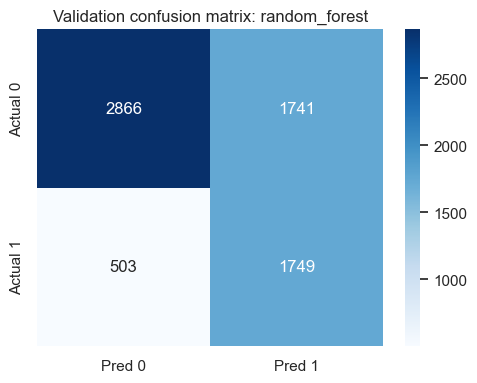

In [25]:
from sklearn.calibration import CalibrationDisplay

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, probability in val_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_val, probability)
    axes[0].plot(recall, precision, label=f'{name} (AP={average_precision_score(y_val, probability):.3f})')
    fpr, tpr, _ = roc_curve(y_val, probability)
    axes[1].plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_val, probability):.3f})')
axes[0].axhline(validation_event_rate, color='black', linestyle='--', label='Event-rate baseline')
axes[0].set(title='Validation precision-recall', xlabel='Recall', ylabel='Precision')
axes[1].plot([0, 1], [0, 1], color='black', linestyle='--')
axes[1].set(title='Validation ROC', xlabel='False positive rate', ylabel='True positive rate')
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
for name, probability in val_probabilities.items():
    CalibrationDisplay.from_predictions(y_val, probability, n_bins=10, strategy='quantile',
                                        name=f'{name} (Brier={brier_score_loss(y_val, probability):.3f})', ax=ax)
ax.set_title('Validation calibration / reliability diagram')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, probability in val_probabilities.items():
    grid = np.unique(np.r_[np.quantile(probability, np.linspace(0, 1, 101)), 0.5,
                           validation_thresholds[name]])
    predicted = probability[:, None] >= grid[None, :]
    alert_share = predicted.mean(axis=0)
    true_positive = (predicted & (y_val.to_numpy()[:, None] == 1)).sum(axis=0)
    recall_values = true_positive / max(int(y_val.sum()), 1)
    precision_values = true_positive / np.maximum(predicted.sum(axis=0), 1)
    axes[0].plot(grid, recall_values, label=name)
    axes[0].scatter(validation_thresholds[name],
                    score_at_threshold(y_val.to_numpy(), probability, validation_thresholds[name])['recall'],
                    s=18)
    axes[1].plot(alert_share, precision_values, marker='.', markersize=2, label=name)
axes[0].set(xlabel='Threshold', ylabel='Recall', title='Recall by threshold (F1-max marked)')
axes[1].axvline(ALERT_SHARE_REFERENCE, color='black', linestyle='--', label='20% reference only')
axes[1].set(xlabel='Alert share', ylabel='Precision', title='Precision vs queue share')
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

cv_plot = cv_results[[f'{folds[i][0]}_pr_auc' for i in range(len(folds))]].T
cv_plot.plot(marker='o', figsize=(9, 4), title='Best-trial temporal CV PR-AUC by fold')
plt.ylabel('Average precision'); plt.xlabel('Temporal validation fold'); plt.tight_layout(); plt.show()

plot_metrics = validation_metrics.loc[[n for n in validation_metrics.index if n != 'constant_event_rate'],
                                      ['validation_pr_auc', 'validation_roc_auc', 'validation_brier']]
plot_metrics.plot(kind='bar', subplots=True, layout=(1, 3), figsize=(15, 4), legend=False,
                  title=['Validation PR-AUC', 'Validation ROC-AUC', 'Validation Brier (lower is better)'])
plt.tight_layout(); plt.show()

selected_prob = val_probabilities[selected_model_name]
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_val, selected_prob >= selected_threshold, labels=[0, 1]),
            annot=True, fmt='d', cmap='Blues', xticklabels=['Pred 0', 'Pred 1'],
            yticklabels=['Actual 0', 'Actual 1'], ax=ax)
ax.set_title(f'Validation confusion matrix: {selected_model_name}'); plt.tight_layout(); plt.show()


,segment_type,segment,n,event_rate,pr_auc,roc_auc,precision,recall,alert_share,alerts_in_group,queue_per_1000
0,market_segment,Corporate,337,0.106825,0.196417,0.627584,1.000000,0.027778,0.002967,1,2.967359
1,market_segment,Direct,605,0.226446,0.398093,0.623160,0.909091,0.072993,0.018182,11,18.181818
2,market_segment,Offline TA/TO,877,0.115165,0.265607,0.686932,1.000000,0.009901,0.001140,1,1.140251
3,market_segment,Online TA,4922,0.398618,0.602486,0.711975,0.499856,0.885321,0.706014,3475,706.013816
4,lead_time_band,0-7d,1103,0.113327,0.205580,0.544127,0.800000,0.032000,0.004533,5,4.533092
5,lead_time_band,8-30d,1485,0.282155,0.498523,0.698471,0.408971,0.739857,0.510438,758,510.437710
6,lead_time_band,31-90d,2334,0.344901,0.532548,0.719047,0.477915,0.819876,0.591688,1381,591.688089
7,lead_time_band,91-180d,1040,0.450000,0.555904,0.636704,0.539683,0.871795,0.726923,756,726.923077
8,lead_time_band,180d+,897,0.484950,0.718804,0.730184,0.622034,0.843678,0.657748,590,657.748049


Lead-time subgroup results are diagnostic only until lead_time is verified as-of the intended prediction time.


,feature,importance_mean,importance_std
38,agent_top,0.085558,0.003121
4,booking_month,0.033197,0.003065
33,market_segment,0.023539,0.001014
35,customer_type,0.018418,0.002920
1,lead_time_log,0.016018,0.000515
0,lead_time,0.014246,0.000676
2,is_last_minute,0.013981,0.000995
12,total_nights,0.011178,0.002232
37,meal,0.010567,0.001562
34,distribution_channel,0.009636,0.002214


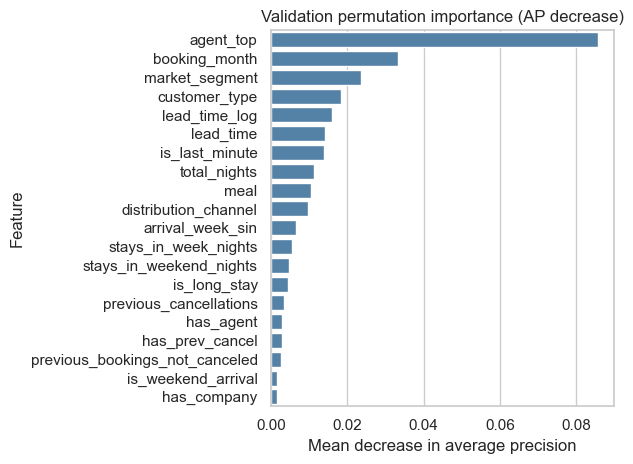

In [26]:
def subgroup_metrics(frame, probability, group_col, threshold, min_n=MIN_SUBGROUP_SIZE):
    records = []
    labels = frame['is_canceled'].astype(int).to_numpy()
    for group, positions in frame.groupby(group_col, dropna=False, observed=True).indices.items():
        positions = np.asarray(positions, dtype=int)
        if len(positions) < min_n:
            continue
        y_group, p_group = labels[positions], probability[positions]
        pred_group = p_group >= threshold
        both_classes = np.unique(y_group).size == 2
        records.append({'segment_type': group_col, 'segment': str(group), 'n': len(positions),
                        'event_rate': y_group.mean(),
                        'pr_auc': average_precision_score(y_group, p_group) if both_classes else np.nan,
                        'roc_auc': roc_auc_score(y_group, p_group) if both_classes else np.nan,
                        'precision': precision_score(y_group, pred_group, zero_division=0),
                        'recall': recall_score(y_group, pred_group, zero_division=0),
                        'alert_share': pred_group.mean(), 'alerts_in_group': int(pred_group.sum()),
                        'queue_per_1000': pred_group.mean() * 1000})
    return pd.DataFrame(records)

lead_time_band = pd.cut(validation['lead_time'], bins=[-np.inf, 7, 30, 90, 180, np.inf],
                        labels=['0-7d', '8-30d', '31-90d', '91-180d', '180d+'], right=True)
subgroup_frame = validation.copy()
subgroup_frame['lead_time_band'] = lead_time_band
subgroup_results = pd.concat([
    subgroup_metrics(subgroup_frame, selected_prob, 'market_segment', selected_threshold),
    subgroup_metrics(subgroup_frame, selected_prob, 'lead_time_band', selected_threshold)
], ignore_index=True)
display(subgroup_results)
print('Lead-time subgroup results are diagnostic only until lead_time is verified as-of the intended prediction time.')

importance_features = baseline_features if selected_model_name == 'baseline_logistic' else feature_cols
importance = permutation_importance(fitted_models[selected_model_name], X_val[importance_features], y_val,
                                    scoring='average_precision', n_repeats=5, random_state=SEED,
                                    n_jobs=-1)
feature_importance = pd.DataFrame({'feature': importance_features,
                                   'importance_mean': importance.importances_mean,
                                   'importance_std': importance.importances_std})
feature_importance = feature_importance.sort_values('importance_mean', ascending=False)
display(feature_importance.head(20))
sns.barplot(data=feature_importance.head(20), x='importance_mean', y='feature', color='steelblue')
plt.title('Validation permutation importance (AP decrease)')
plt.xlabel('Mean decrease in average precision'); plt.ylabel('Feature')
plt.tight_layout(); plt.show()


## 6. Fit model cuối, mở test một lần và tạo file output

Sau khi model/threshold đã được chọn trên validation, fit lại model đã chọn trên train + validation. Threshold vẫn giữ nguyên theo validation. Test 2017 chỉ được dùng ở phần này để đánh giá lần cuối và ghi ra prediction file; do EDA trước đây đã xem nhãn 2017, kết quả test không được diễn giải như một holdout lịch sử hoàn toàn mới.


In [27]:
fit_cohort = pd.concat([train, validation]).sort_values('arrival_date')
if selected_model_name == 'baseline_logistic':
    final_model = make_baseline_pipeline()
    final_features = baseline_features
    final_X_fit = fit_cohort[final_features]
    final_X_test = test[final_features]
else:
    final_model = make_pipeline(selected_model_name, best_params[selected_model_name])
    final_features = feature_cols
    final_X_fit = fit_cohort[final_features]
    final_X_test = test[final_features]
final_model.fit(final_X_fit, fit_cohort['is_canceled'].astype(int))
test_probability = final_model.predict_proba(final_X_test)[:, 1]
if not np.isfinite(test_probability).all():
    raise ValueError('Test prediction chứa NaN hoặc infinity.')
if test['is_canceled'].isna().any() or not set(test['is_canceled'].unique()).issubset({0, 1}):
    raise ValueError('Test labels must be binary and non-null at final evaluation.')
y_test = test['is_canceled'].astype(int).to_numpy()
test_threshold_metrics = score_at_threshold(y_test, test_probability, selected_threshold)
test_metrics = {'model': selected_model_name, 'threshold_frozen_from_validation': selected_threshold,
                'test_rows': len(test), 'test_event_rate_baseline': float(y_test.mean()),
                'test_pr_auc': average_precision_score(y_test, test_probability),
                'test_roc_auc': roc_auc_score(y_test, test_probability),
                'test_brier': brier_score_loss(y_test, test_probability), **test_threshold_metrics}
test_metrics_df = pd.DataFrame([test_metrics])
display(test_metrics_df.T.rename(columns={0: 'test result'}))
print('Test PR-AUC above event-rate baseline indicates ranking lift; inspect Brier, confusion matrix and queue before any deployment decision.')

test_predictions = pd.DataFrame({'booking_id': test['booking_id'].to_numpy(),
                                 'arrival_date': test['arrival_date'].to_numpy(),
                                 'is_canceled': y_test, 'predicted_probability': test_probability,
                                 'threshold': selected_threshold,
                                 'predicted_label': (test_probability >= selected_threshold).astype(int)})
cv_results.reset_index().to_csv(OUTPUT_DIR / 'temporal_cv_results.csv', index=False)
validation_metrics.reset_index().to_csv(OUTPUT_DIR / 'validation_metrics.csv', index=False)
validation_predictions_all.to_csv(OUTPUT_DIR / 'validation_predictions_all_models.csv', index=False)
validation_predictions_best.to_csv(OUTPUT_DIR / 'validation_predictions_best_model.csv', index=False)
subgroup_results.to_csv(OUTPUT_DIR / 'subgroup_metrics.csv', index=False)
feature_importance.to_csv(OUTPUT_DIR / 'feature_importance.csv', index=False)
test_metrics_df.to_csv(OUTPUT_DIR / 'test_metrics.csv', index=False)
test_predictions.to_csv(OUTPUT_DIR / 'test_predictions_best_model.csv', index=False)
joblib.dump(final_model, OUTPUT_DIR / 'final_model.joblib')

selection_md = f'''# Model evaluation report\n\n## Scope and caveats\n- Selected model: **{selected_model_name}**.\n- Final fit: all train + validation rows through 2016-12-31; test begins 2017-01-01.\n- Validation and test were previously inspected in notebook 03 EDA; test is not historically untouched.\n- Dataset is a near-arrival snapshot; results are retrospective and not a production performance guarantee.\n- Frozen threshold: **{selected_threshold:.6f}**, selected on validation to maximize F1; no hard alert-share cap.\n- Validation alert share: **{validation_metrics.loc[selected_model_name, 'alert_share']:.1%}**.\n\n## Validation model comparison\n{selection_table.reset_index().to_string(index=False)}\n\n## Test evaluation (single final evaluation)\n{test_metrics_df.to_string(index=False)}\n\n## Selection rule\nTake candidates within 0.01 of the best validation AP; tie-break by lower validation Brier, higher temporal CV mean AP, lower fold variability, then model simplicity. No hard alert-share constraint; report queue size for operations. No model is selected solely by CV.\n\n## Interpretation checklist\n- Compare PR-AUC with event-rate baseline; report ROC-AUC and Brier alongside threshold metrics.\n- Review precision/recall, confusion matrix, alert share and expected queue per 1,000.\n- Inspect market-segment and lead-time-band subgroup table; small groups (<{MIN_SUBGROUP_SIZE}) are omitted. Lead-time groups are diagnostic until as-of validity is confirmed.\n- Permutation importance is validation-based and associative, not causal.\n- Verify as-of feature availability, calibration drift, operational capacity and false-positive/false-negative costs before deployment.\n'''
selection_md += '\n\n## Temporal CV results\n\n' + cv_results.reset_index().to_string(index=False)
selection_md += '\n\n## Validation subgroup metrics\n\n' + subgroup_results.to_string(index=False)
selection_md += '\n\n## Top validation permutation importance\n\n' + feature_importance.head(15).to_string(index=False) + '\n'
(OUTPUT_DIR / 'model_selection_report.md').write_text(selection_md, encoding='utf-8')
print('Wrote outputs to', OUTPUT_DIR)
print(' - validation_predictions_best_model.csv (requested validation scoring output)')
print(' - test_predictions_best_model.csv, metrics, feature importance, final_model.joblib, model_selection_report.md')


,test result
model,random_forest
threshold_frozen_from_validation,0.485855
test_rows,20399
test_event_rate_baseline,0.343742
test_pr_auc,0.525719
test_roc_auc,0.714158
test_brier,0.224697
precision,0.480757
recall,0.833714
f1,0.609848


Test PR-AUC above event-rate baseline indicates ranking lift; inspect Brier, confusion matrix and queue before any deployment decision.
Wrote outputs to c:\Users\Admin\OneDrive\Desktop\BA-Advance-Project---Group-2\artifacts\modeling
 - validation_predictions_best_model.csv (requested validation scoring output)
 - test_predictions_best_model.csv, metrics, feature importance, final_model.joblib, model_selection_report.md


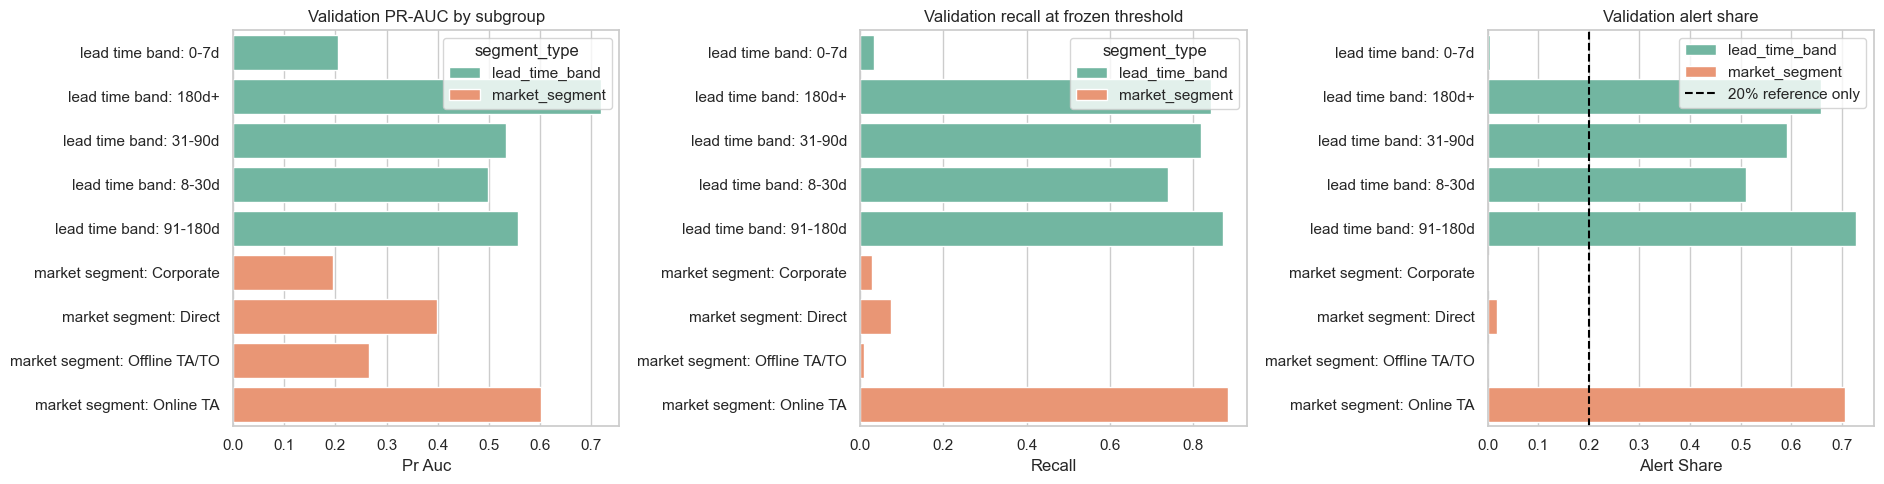

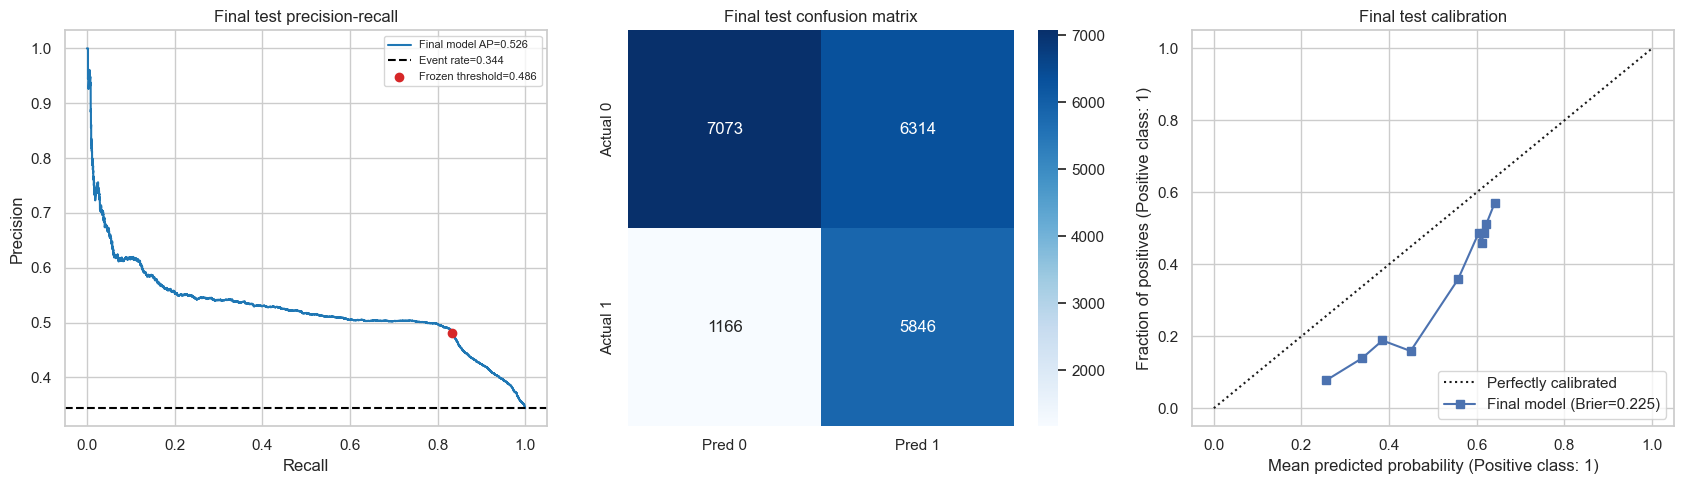

,selected_model,frozen_threshold,test_precision,test_recall,test_alert_share,test_alert_count,expected_alerts_per_1000
0,random_forest,0.485855,0.480757,0.833714,0.596108,12160,596.107652


In [28]:
# Hiển thị subgroup plots và đánh giá cuối trên test sau khi đã khóa model/threshold.
plot_subgroups = subgroup_results.copy()
plot_subgroups['group_label'] = plot_subgroups['segment_type'].str.replace('_', ' ') + ': ' + plot_subgroups['segment']
plot_subgroups = plot_subgroups.sort_values(['segment_type', 'segment'])

fig, axes = plt.subplots(1, 3, figsize=(19, max(5, 0.42 * len(plot_subgroups))))
for ax, metric, title in zip(
    axes,
    ['pr_auc', 'recall', 'alert_share'],
    ['Validation PR-AUC by subgroup', 'Validation recall at frozen threshold', 'Validation alert share'],
):
    sns.barplot(data=plot_subgroups, x=metric, y='group_label', hue='segment_type',
                dodge=False, palette='Set2', ax=ax)
    ax.set_title(title)
    ax.set_xlabel(metric.replace('_', ' ').title())
    ax.set_ylabel('')
    if metric == 'alert_share':
        ax.axvline(ALERT_SHARE_REFERENCE, color='black', linestyle='--', label='20% reference only')
        ax.legend()
plt.tight_layout()
plt.show()

# Test plots are descriptive only; test labels do not affect selection or threshold.
test_precision_curve, test_recall_curve, _ = precision_recall_curve(y_test, test_probability)
test_ap = average_precision_score(y_test, test_probability)
final_operating = score_at_threshold(y_test, test_probability, selected_threshold)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].plot(test_recall_curve, test_precision_curve, color='tab:blue', label=f'Final model AP={test_ap:.3f}')
axes[0].axhline(y_test.mean(), color='black', linestyle='--', label=f'Event rate={y_test.mean():.3f}')
axes[0].scatter(final_operating['recall'], final_operating['precision'], color='tab:red', zorder=3,
                label=f'Frozen threshold={selected_threshold:.3f}')
axes[0].set(title='Final test precision-recall', xlabel='Recall', ylabel='Precision')
axes[0].legend(fontsize=8)

sns.heatmap(confusion_matrix(y_test, test_probability >= selected_threshold, labels=[0, 1]),
            annot=True, fmt='d', cmap='Blues', xticklabels=['Pred 0', 'Pred 1'],
            yticklabels=['Actual 0', 'Actual 1'], ax=axes[1])
axes[1].set_title('Final test confusion matrix')
CalibrationDisplay.from_predictions(y_test, test_probability, n_bins=10, strategy='quantile',
                                    name=f'Final model (Brier={brier_score_loss(y_test, test_probability):.3f})',
                                    ax=axes[2])
axes[2].set_title('Final test calibration')
plt.tight_layout()
plt.show()

display(pd.DataFrame([{
    'selected_model': selected_model_name,
    'frozen_threshold': selected_threshold,
    'test_precision': final_operating['precision'],
    'test_recall': final_operating['recall'],
    'test_alert_share': final_operating['alert_share'],
    'test_alert_count': final_operating['alerts_in_cohort'],
    'expected_alerts_per_1000': final_operating['queue_per_1000'],
}]))

## Deliverables khi chạy

Thư mục `artifacts/modeling/` sẽ chứa predictions của mọi model và model tốt nhất trên validation, predictions/evaluation trên test, temporal CV + validation/subgroup/test metrics, permutation importance, serialized final model và `model_selection_report.md`. Trước khi dùng model, cần xác minh snapshot/as-of semantics, chọn chi phí vận hành threshold với business owner và chạy quy trình scoring trên dữ liệu mới có schema tương thích.
